# Section B: Clustering Track (Unsupervised Learning)
**Dataset:** Elite Sports Cars in Data
**Objective:** Group sports cars based on key performance metrics and price to discover inherent market segments.
*Per the Review 2 rubric, this is purely unsupervised learning. No target labels are used during model fitting.*

In [10]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Clustering & Metrics
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Preprocessing & Dimensionality Reduction
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import scipy.cluster.hierarchy as sch

# Plot formatting
sns.set_style("whitegrid")
sns.set_palette("colorblind")
import warnings
warnings.filterwarnings('ignore')

### 1. Data Loading and Feature Selection
To keep our clusters interpretable and focused on our problem statement, we isolate four core numerical features representing performance and cost. Because clustering algorithms rely on distance (like Euclidean distance), we must scale these features so a variable like Price (in the thousands) doesn't overpower Acceleration (small decimals).

In [11]:
# Load the dataset using the exact file name
df = pd.read_csv('../data/Elite Sports Cars in Data.csv')

# Select only the features relevant to "Performance and Price"
features = ['Horsepower', 'Top_Speed', 'Acceleration_0_100', 'Price']
X_raw = df[features]

# Handle any potential missing values by filling with the median
X_raw = X_raw.fillna(X_raw.median())

# Scale the features so all metrics have equal weight
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print(f"Clustering Dataset Shape: {X_scaled.shape}")

Clustering Dataset Shape: (5000, 4)


### 2. K-Means Clustering & The Elbow Curve (Section B2)
To find the optimal number of clusters ($k$), we plot the Inertia (Within-Cluster Sum of Squares) for $k$ ranging from 2 to 10. We are looking for the "elbow" point where the graph bends.

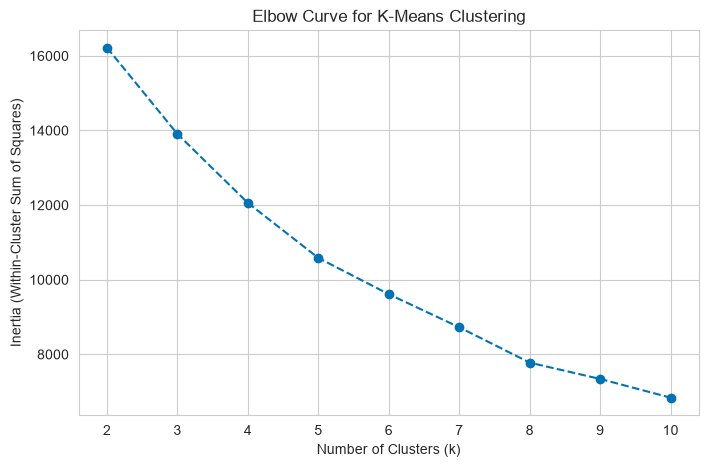

In [12]:
inertia = []
k_range = range(2, 11)

for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_temp.fit(X_scaled)
    inertia.append(kmeans_temp.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', linestyle='--')
plt.title('Elbow Curve for K-Means Clustering')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.xticks(k_range)
plt.show()

**Observation:** Based on the Elbow curve, we will select $k=3$ (Adjust this number in the code below if your plot shows a sharper bend at 4). We will now fit the K-Means model and calculate the three mandatory evaluation metrics.

In [13]:
# Set optimal K based on the Elbow curve observation
OPTIMAL_K = 3 

# Fit the final K-Means model
kmeans = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Calculate mandatory K-Means metrics
km_sil = silhouette_score(X_scaled, kmeans_labels)
km_db = davies_bouldin_score(X_scaled, kmeans_labels)
km_ch = calinski_harabasz_score(X_scaled, kmeans_labels)

print(f"--- K-Means Metrics (k={OPTIMAL_K}) ---")
print(f"Silhouette Score: {km_sil:.4f}")
print(f"Davies-Bouldin Index: {km_db:.4f}")
print(f"Calinski-Harabasz Index: {km_ch:.2f}")

--- K-Means Metrics (k=3) ---
Silhouette Score: 0.1759
Davies-Bouldin Index: 1.7061
Calinski-Harabasz Index: 1095.17


### 3. Agglomerative Hierarchical Clustering (Section B2)
Next, we use hierarchical clustering with the `ward` linkage method. The Dendrogram visualises how individual cars are grouped step-by-step into larger clusters. We truncate the plot slightly so it renders cleanly.

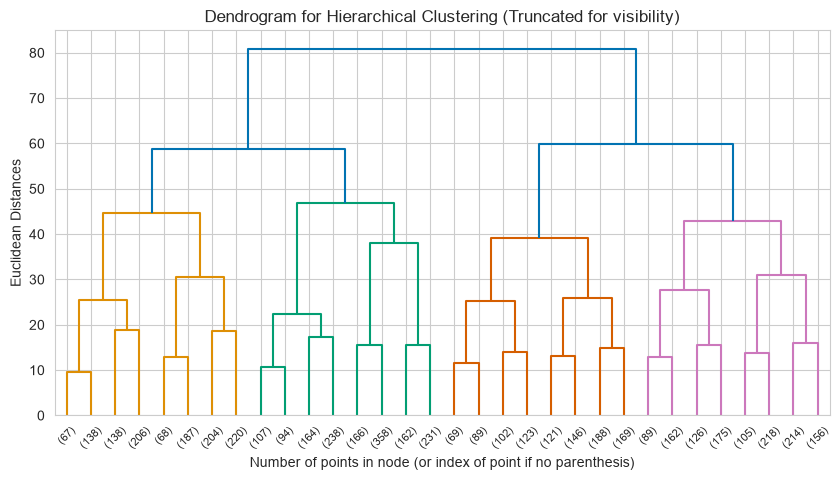

In [14]:
plt.figure(figsize=(10, 5))
plt.title("Dendrogram for Hierarchical Clustering (Truncated for visibility)")
plt.xlabel("Number of points in node (or index of point if no parenthesis)")
plt.ylabel("Euclidean Distances")

# Generate and plot the dendrogram using Ward's method
dendro = sch.dendrogram(sch.linkage(X_scaled, method='ward'), truncate_mode='level', p=4)
plt.show()

Now we fit the Agglomerative Clustering model using the same $k$ value as K-Means. Per the project guidelines, we will briefly compare two different linkage strategies (`ward` vs `average`) using the Silhouette Score to see which creates better-defined clusters.

In [15]:
# Compare linkage strategies
hc_ward = AgglomerativeClustering(n_clusters=OPTIMAL_K, metric='euclidean', linkage='ward')
labels_ward = hc_ward.fit_predict(X_scaled)
sil_ward = silhouette_score(X_scaled, labels_ward)

hc_avg = AgglomerativeClustering(n_clusters=OPTIMAL_K, metric='euclidean', linkage='average')
labels_avg = hc_avg.fit_predict(X_scaled)
sil_avg = silhouette_score(X_scaled, labels_avg)

print(f"Linkage Comparison (Silhouette Scores):")
print(f"Ward Linkage: {sil_ward:.4f}")
print(f"Average Linkage: {sil_avg:.4f}")

# Proceeding with Ward for the final metrics as it typically performs better
hc_labels = labels_ward
hc_sil = sil_ward
hc_db = davies_bouldin_score(X_scaled, hc_labels)
hc_ch = calinski_harabasz_score(X_scaled, hc_labels)

print(f"\n--- Final Hierarchical Clustering Metrics (Ward, k={OPTIMAL_K}) ---")
print(f"Silhouette Score: {hc_sil:.4f}")
print(f"Davies-Bouldin Index: {hc_db:.4f}")
print(f"Calinski-Harabasz Index: {hc_ch:.2f}")

Linkage Comparison (Silhouette Scores):
Ward Linkage: 0.1363
Average Linkage: 0.1220

--- Final Hierarchical Clustering Metrics (Ward, k=3) ---
Silhouette Score: 0.1363
Davies-Bouldin Index: 1.8078
Calinski-Harabasz Index: 846.37


### 4. Cluster Visualisation: PCA (Section B3)
Because our features (Horsepower, Speed, Acceleration, Price) exist in 4 dimensions, we cannot plot them directly. We use Principal Component Analysis (PCA) to compress the data into 2 dimensions for a side-by-side scatter plot.

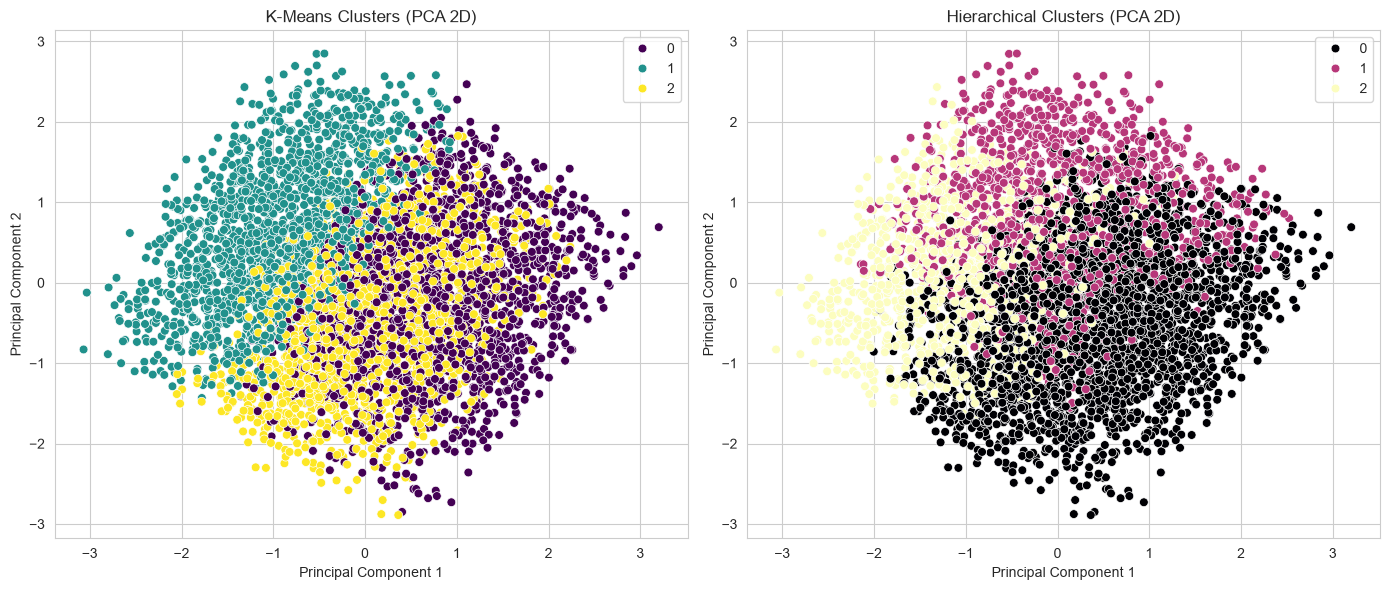

In [16]:
# Compress 4 dimensions down to 2 using PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Create subplots for side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot K-Means Clusters
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans_labels, palette='viridis', ax=axes[0], s=40)
axes[0].set_title('K-Means Clusters (PCA 2D)')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')

# Plot Hierarchical Clusters
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=hc_labels, palette='magma', ax=axes[1], s=40)
axes[1].set_title('Hierarchical Clusters (PCA 2D)')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')

plt.tight_layout()
plt.show()

### 5. Cluster Visualisation: t-SNE (Section B3)
Finally, we apply t-SNE to the K-Means clusters. While PCA is great for global structure, t-SNE is highly effective at showing local groupings and non-linear relationships in the data.

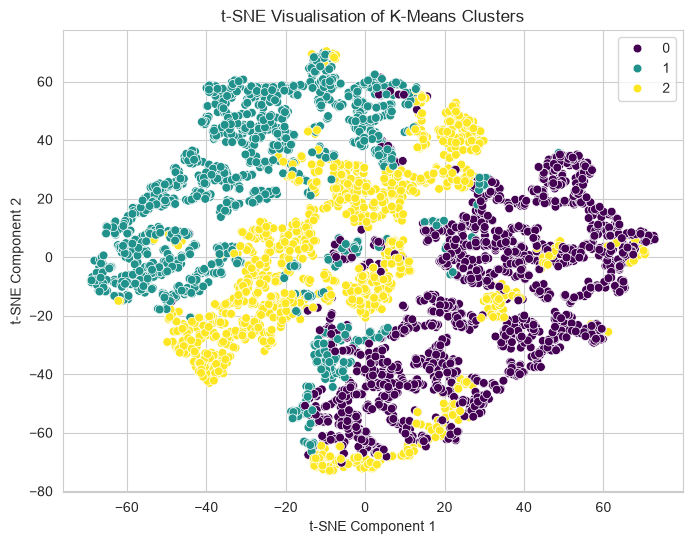

In [17]:
# Fit t-SNE to compress the data into 2 components
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

# Plot t-SNE Results
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=kmeans_labels, palette='viridis', s=40)
plt.title('t-SNE Visualisation of K-Means Clusters')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.show()

### 6. Final Results Comparison
Consolidating the evaluation metrics for both algorithms into a single table. 
* Higher Silhouette and Calinski-Harabasz scores indicate better, more distinct clusters.
* Lower Davies-Bouldin scores indicate better clustering.

In [18]:
# Create a DataFrame summarizing the clustering metrics
results_df = pd.DataFrame({
    'Algorithm': ['K-Means', 'Hierarchical (Ward)'],
    'Silhouette Score': [km_sil, hc_sil],
    'Davies-Bouldin Index': [km_db, hc_db],
    'Calinski-Harabasz Index': [km_ch, hc_ch]
})

display(results_df)

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,0.175897,1.706132,1095.171291
1,Hierarchical (Ward),0.136315,1.807848,846.365770
